# Change-vector magnitude

This notebook scores one measurement: how far the color of a known building moved between a pre-event satellite image and a post-event image. At each pixel the change vector is the difference of the two color triples, and its length is

\[
M(p) = \left\| I_{\mathrm{post}}(p + \Delta) - I_{\mathrm{pre}}(p) \right\|_2 = \sqrt{\sum_{c \in \{B, G, R\}} \left( I^{c}_{\mathrm{post}}(p + \Delta) - I^{c}_{\mathrm{pre}}(p) \right)^2}.
\]

The reported score is the mean of \(M\) over the interior mask of the polygon. A higher score means the roof color changed more.

Change-vector analysis is the multiband difference of Malila (1980) and the change-detection review of Singh (1989). Unlike correlation loss, it keeps the size of the change: a roof that turns from bright to dark, or from red to gray, scores high even if its pattern survives. That is also its weakness, because a shadow or a roof displaced by the viewing angle moves color without any damage. The figures below show one case of each.

The notebook does not read the other four scores and does not choose weights. Mexico City and Palu are not opened. Damage labels are joined only after the score exists, so the figures and the partial table can be drawn. The score function itself takes two arrays of paired color samples and returns a number.

## Dataset and the shared subset

The xView2 challenge training set is `Dataset/train` next to the project folder that contains this notebook, or `Dataset/train_images_labels_targets/train` when the archive was unpacked as downloaded. `XVIEW2_ROOT` overrides that path, and the same `Downloads` folders as the morphology notebook are checked as a fallback. Each pair is a pre-event PNG, a post-event PNG, and a post-disaster JSON. Polygons come from `features.xy`: pixel coordinates in the WKT, `uid` as the building id, and `subtype` as the damage label. Unclassified polygons are dropped.

Results for this score are written under `outputs/change_vector/progress/`, with `tables/` for the CSV and `figures/` for the plots. `outputs/change_vector/final/` is left for the later pass over the remaining practice pairs. The same layout is used by the other scores: `correlation_loss`, `morphology`, `lab_histogram`, `texture_contrast`, and, once those tables exist, `fusion`.

The 13 pairs below are the shared practice subset, the same list as the correlation and morphology notebooks. This run is incomplete. It is not the evaluation.

In [1]:
import csv
import json
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np


def github_root():
    here = Path.cwd().resolve()
    markers = ("change_vector.ipynb", "correlation_loss.ipynb")
    for candidate in [here, *here.parents]:
        for name in markers:
            if (candidate / "src" / name).is_file():
                return candidate
        for nested in sorted(path for path in candidate.iterdir() if path.is_dir()):
            for name in markers:
                if (nested / "src" / name).is_file():
                    return nested
    raise FileNotFoundError("Project root containing src/change_vector.ipynb not found")


def resolve_data_root(project_root):
    if os.environ.get("XVIEW2_ROOT"):
        return Path(os.environ["XVIEW2_ROOT"]).resolve()
    candidates = [
        (project_root.parent / "Dataset" / "train").resolve(),
        (project_root.parent / "Dataset" / "train_images_labels_targets" / "train").resolve(),
        (Path.home() / "Downloads" / "Dataset" / "train").resolve(),
        (Path.home() / "Downloads" / "train").resolve(),
        (Path.home() / "Downloads" / "train_images_labels_targets" / "train").resolve(),
    ]
    for candidate in candidates:
        if (candidate / "images").is_dir() and (candidate / "labels").is_dir():
            return candidate
    return candidates[0]


GITHUB = github_root()
DATA_ROOT = resolve_data_root(GITHUB)
IMAGE_DIR = DATA_ROOT / "images"
LABEL_DIR = DATA_ROOT / "labels"
SCORE_DIR = GITHUB / "outputs" / "change_vector"
TABLE_DIR = SCORE_DIR / "progress" / "tables"
FIGURE_DIR = SCORE_DIR / "progress" / "figures"
for folder in (
    TABLE_DIR,
    FIGURE_DIR,
    SCORE_DIR / "final" / "tables",
    SCORE_DIR / "final" / "figures",
):
    folder.mkdir(parents=True, exist_ok=True)

SUBSET = [
    "santa-rosa-wildfire_00000006",
    "santa-rosa-wildfire_00000007",
    "santa-rosa-wildfire_00000011",
    "santa-rosa-wildfire_00000002",
    "socal-fire_00000081",
    "socal-fire_00000082",
    "socal-fire_00000090",
    "socal-fire_00000002",
    "midwest-flooding_00000143",
    "midwest-flooding_00000001",
    "midwest-flooding_00000003",
    "guatemala-volcano_00000025",
    "guatemala-volcano_00000006",
]

if not IMAGE_DIR.is_dir() or not LABEL_DIR.is_dir():
    raise FileNotFoundError(
        f"xView2 train directory not found at {DATA_ROOT}. "
        "Place Dataset/train next to the project folder, place train/ in Downloads, or set XVIEW2_ROOT."
    )

## Histogram matching

Singh (1989) and Lu et al. (2004) both require the two dates to share an intensity scale before a difference, or a correlation, means a change of the surface. Histogram matching is the point operation that does that. Lab 1 builds a histogram by counting gray levels and a cumulative distribution by `cumsum`. Gonzalez and Woods turn those two cumulative distributions into a lookup table: each post-event gray level is replaced by the pre-event gray level with the same cumulative value. Pratt treats the same table as a point operation \(s = T(r)\).

The match is done independently on the three color channels, with 256 bins. Pixels that are very dark and locally smooth are left out of both histograms, so a large dark water or shadow region does not set the roof scale. The constants used here are provisional and were not chosen on Mexico City or Palu: luminance below 40, and a 5 by 5 local standard deviation below 8. The lookup table is still applied to every pixel. Local standard deviation is the sample spread inside a box window, the same kind of neighborhood statistic used when Lab 1 and the spatial-filtering lectures separate a flat region from a textured one.

In [2]:
def luminance(image):
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


def local_std(gray, window=5):
    values = gray.astype(np.float64)
    mean = cv2.blur(values, (window, window))
    second = cv2.blur(values * values, (window, window))
    variance = np.maximum(second - mean * mean, 0.0)
    return np.sqrt(variance)


def usable_pixels(image):
    gray = luminance(image)
    dark = gray < 40
    smooth = local_std(gray) < 8
    return ~(dark & smooth)


def match_channel(source, reference, source_keep, reference_keep):
    source_hist = np.bincount(source[source_keep], minlength=256).astype(np.float64)
    reference_hist = np.bincount(reference[reference_keep], minlength=256).astype(np.float64)
    if source_hist.sum() == 0 or reference_hist.sum() == 0:
        return source.copy()
    source_cdf = np.cumsum(source_hist) / source_hist.sum()
    reference_cdf = np.cumsum(reference_hist) / reference_hist.sum()
    lookup = np.searchsorted(reference_cdf, source_cdf, side="left")
    lookup = np.clip(lookup, 0, 255).astype(np.uint8)
    return lookup[source]


def histogram_match(post, pre):
    source_keep = usable_pixels(post)
    reference_keep = usable_pixels(pre)
    matched = np.empty_like(post)
    for channel in range(3):
        matched[:, :, channel] = match_channel(
            post[:, :, channel],
            pre[:, :, channel],
            source_keep,
            reference_keep,
        )
    return matched

## Local alignment

xBD pairs are already registered, but a roof can still sit a few pixels away from its pre-event footprint because the satellite is off-nadir. The workflow allows a shift of at most 4 pixels, and only when the short side of the polygon is at least 12 pixels. Smaller roofs are left where they are.

The shift is the peak of normalized cross-correlation, which is the template match in Lab 3. For a template \(T\) and a patch \(P\), both with their means removed,

\[
\mathrm{NCC} = \frac{\sum (T-\bar T)(P-\bar P)}{\sqrt{\sum (T-\bar T)^2 \sum (P-\bar P)^2}}.
\]

Lab 3 writes that sum in a loop. Here the search window is only 9 by 9, so `cv2.matchTemplate` with `TM_CCOEFF_NORMED` evaluates the same coefficient. Szeliski's frequency-domain phase correlation is the whole-image reserve and is not used on this subset. A flat template has no peak, and the shift stays zero.

In [3]:
def polygon_points(wkt):
    start = wkt.find("((")
    end = wkt.rfind("))")
    body = wkt[start + 2:end]
    points = []
    for piece in body.split(","):
        parts = piece.split()
        points.append([float(parts[0]), float(parts[1])])
    return np.asarray(points, dtype=np.float64)


def short_side(points):
    width = float(points[:, 0].max() - points[:, 0].min())
    height = float(points[:, 1].max() - points[:, 1].min())
    return min(width, height)


def best_shift(pre_gray, post_gray, points):
    if short_side(points) < 12:
        return 0, 0
    height, width = pre_gray.shape
    x0 = max(0, int(np.floor(points[:, 0].min())))
    y0 = max(0, int(np.floor(points[:, 1].min())))
    x1 = min(width, int(np.ceil(points[:, 0].max())) + 1)
    y1 = min(height, int(np.ceil(points[:, 1].max())) + 1)
    if x1 - x0 < 2 or y1 - y0 < 2:
        return 0, 0
    template = pre_gray[y0:y1, x0:x1]
    if float(template.std()) < 1.0:
        return 0, 0
    search_x0 = max(0, x0 - 4)
    search_y0 = max(0, y0 - 4)
    search_x1 = min(width, x1 + 4)
    search_y1 = min(height, y1 + 4)
    search = post_gray[search_y0:search_y1, search_x0:search_x1]
    if search.shape[0] < template.shape[0] or search.shape[1] < template.shape[1]:
        return 0, 0
    scores = cv2.matchTemplate(search, template, cv2.TM_CCOEFF_NORMED)
    if not np.isfinite(scores).any():
        return 0, 0
    scores = np.nan_to_num(scores, nan=-1.0)
    _, _, _, peak = cv2.minMaxLoc(scores)
    dx = int(np.clip(peak[0] - (x0 - search_x0), -4, 4))
    dy = int(np.clip(peak[1] - (y0 - search_y0), -4, 4))
    return dx, dy

## Polygon interior and the change-vector score

The polygon is filled on the image grid and eroded by one pixel with a 3 by 3 square, the same interior mask as the other scores. If fewer than 40 pixels survive, the original polygon is used and the building is still scored.

Inside that mask the score uses all three color channels of the pre-event image and of the histogram-matched, shifted post-event image, on the 0–255 scale. Let \(a_i\) and \(b_i\) be the paired color triples. The score is

\[
\mathrm{score} = \frac{1}{n} \sum_{i=1}^{n} \left\| b_i - a_i \right\|_2 .
\]

It lies between 0 and \(255\sqrt{3} \approx 441.7\). An intact roof stays near the noise level after the brightness match. A burned, collapsed, or replaced roof moves far. Because the match is global, a roof that falls into a new shadow, or a roof whose pixels now show a wall or the ground because the view changed, also moves far. That is the false-alarm case drawn below.

In [4]:
def polygon_mask(points, shape):
    mask = np.zeros(shape, dtype=np.uint8)
    contour = np.round(points).astype(np.int32)
    cv2.fillPoly(mask, [contour], 1)
    return mask


def interior_mask(points, shape):
    mask = polygon_mask(points, shape)
    eroded = cv2.erode(mask, np.ones((3, 3), np.uint8), iterations=1)
    if int(eroded.sum()) < 40:
        return mask
    return eroded


def paired_colors(pre, post, mask, dx, dy):
    rows, cols = np.nonzero(mask)
    shifted_rows = rows + dy
    shifted_cols = cols + dx
    height, width = pre.shape[:2]
    keep = (
        (shifted_rows >= 0)
        & (shifted_rows < height)
        & (shifted_cols >= 0)
        & (shifted_cols < width)
    )
    rows = rows[keep]
    cols = cols[keep]
    shifted_rows = shifted_rows[keep]
    shifted_cols = shifted_cols[keep]
    return pre[rows, cols], post[shifted_rows, shifted_cols]


def paired_values(pre_gray, post_gray, mask, dx, dy):
    return paired_colors(pre_gray, post_gray, mask, dx, dy)


def change_vector_magnitude(pre_values, post_values):
    difference = post_values.astype(np.float64) - pre_values.astype(np.float64)
    return float(np.sqrt((difference * difference).sum(axis=1)).mean())

## Scoring the subset

Each pair is histogram-matched once. The shift for each polygon is found on luminance, exactly as in the other notebooks, and then applied to the color image. The CSV columns are `image_id`, `building_id`, `score`, and `n_pixels`. `n_pixels` is the number of color samples that entered the mean. The label is stored in memory for the next sections and is not an argument of `change_vector_magnitude`.

Two diagnostics are also kept in memory, only to choose and caption the false-alarm figure: the mean luminance change inside the polygon, and the share of the squared change that lies along the gray axis \((1,1,1)/\sqrt{3}\), which is pure brightness. They are not written to the CSV.

In [5]:
def load_pair(image_id):
    pre = cv2.imread(str(IMAGE_DIR / f"{image_id}_pre_disaster.png"), cv2.IMREAD_COLOR)
    post = cv2.imread(str(IMAGE_DIR / f"{image_id}_post_disaster.png"), cv2.IMREAD_COLOR)
    if pre is None or post is None:
        raise FileNotFoundError(image_id)
    label_path = LABEL_DIR / f"{image_id}_post_disaster.json"
    label = json.loads(label_path.read_text())
    return pre, post, label["features"]["xy"]


def brightness_share(pre_values, post_values):
    difference = post_values.astype(np.float64) - pre_values.astype(np.float64)
    total = float((difference * difference).sum())
    if total == 0:
        return 0.0
    gray = difference.sum(axis=1) / np.sqrt(3.0)
    return float((gray * gray).sum() / total)


rows = []
for image_id in SUBSET:
    pre, post, features = load_pair(image_id)
    matched = histogram_match(post, pre)
    pre_gray = luminance(pre)
    post_gray = luminance(matched)
    for feature in features:
        subtype = feature["properties"]["subtype"]
        if subtype == "un-classified":
            continue
        points = polygon_points(feature["wkt"])
        if len(points) < 3:
            continue
        mask = interior_mask(points, pre_gray.shape)
        if int(mask.sum()) == 0:
            continue
        dx, dy = best_shift(pre_gray, post_gray, points)
        pre_values, post_values = paired_colors(pre, matched, mask, dx, dy)
        if pre_values.size == 0:
            continue
        pre_lum, post_lum = paired_values(pre_gray, post_gray, mask, dx, dy)
        rows.append({
            "image_id": image_id,
            "building_id": feature["properties"]["uid"],
            "score": change_vector_magnitude(pre_values, post_values),
            "n_pixels": int(pre_values.shape[0]),
            "pre_mean": float(pre_lum.mean()),
            "lum_change": float(post_lum.astype(np.float64).mean() - pre_lum.astype(np.float64).mean()),
            "bright_share": brightness_share(pre_values, post_values),
            "subtype": subtype,
            "dx": dx,
            "dy": dy,
            "points": points,
        })

csv_path = TABLE_DIR / "change_vector_subset.csv"
with csv_path.open("w", newline="") as handle:
    writer = csv.DictWriter(handle, fieldnames=["image_id", "building_id", "score", "n_pixels"])
    writer.writeheader()
    for row in rows:
        writer.writerow({
            "image_id": row["image_id"],
            "building_id": row["building_id"],
            "score": f"{row['score']:.6f}",
            "n_pixels": row["n_pixels"],
        })

print(f"buildings {len(rows)}")
print(f"csv {csv_path.resolve()}")

buildings 878
csv D:\CS419-Project\CS419-Project\outputs\change_vector\progress\tables\change_vector_subset.csv


## Figures

Each example row is one building: the pre-event crop, the post-event crop after the histogram match and the shift found for that polygon, and the magnitude \(M\) at every pixel of the crop. All magnitude panels share one gray scale, from 0 to the 99th percentile of \(M\) inside the subset's polygons, so dark means a large change in every row. The outline is the post-disaster polygon. Buildings used in the panels have a short side of at least 24 pixels and at least 250 interior pixels.

`examples_destroyed.png` is the real loss: the two highest-scoring destroyed buildings from different practice events.

`examples_intact.png` is the false alarm: undamaged buildings that score like destruction. Only undamaged roofs that score at least the median destroyed score are considered, so every row is a real false alarm. Each of them gets two quick checks. The **shift check** slides the post-event patch up to 12 pixels, three times the allowed alignment, and records how much of the score that removes. A large drop means the roof is intact but displaced. A best position on the edge of that window is not a displacement of the roof, only a better match with some other surface, so it does not count. The **shadow check** asks whether most of the change is pure brightness and the roof got darker. The figure shows the highest-scoring shift case and the highest-scoring shadow case, or the next highest-scoring of those roofs if one kind is missing, with a caption that says neither check fired. These checks only rank candidates for the drawing, and the caption names the one that fired. They are not part of the score.

The charts summarize the same 13 pairs as the other notebooks: the score by damage class, the no-damage and destroyed histograms, and the mean score on each practice event. Mexico City and Palu are not in these figures.

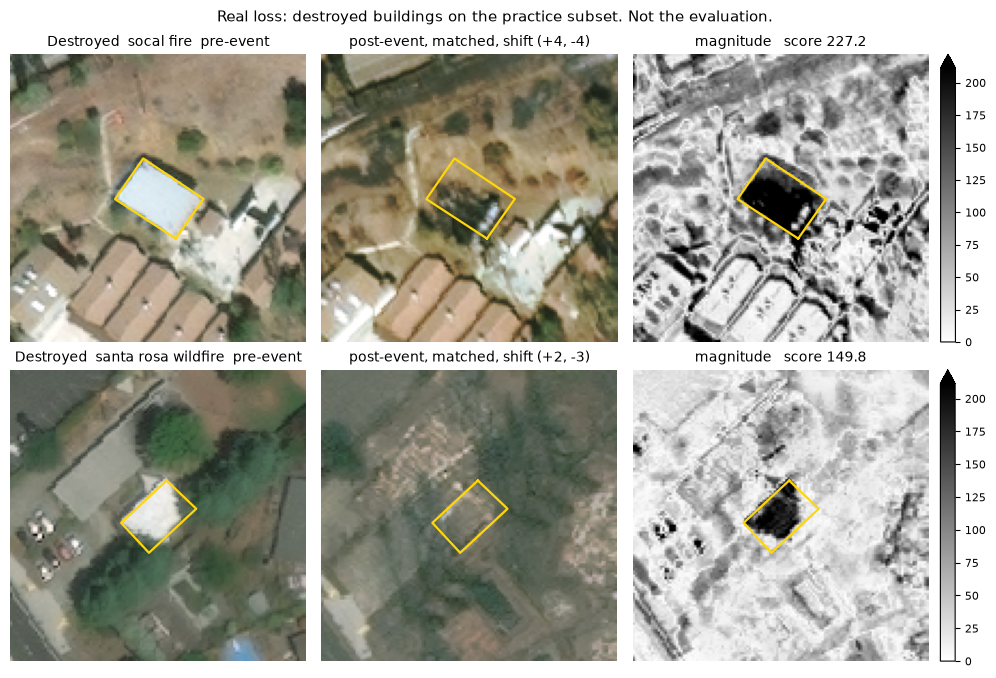

socal-fire_00000090 0ced6b3c-1637-4043-925e-eef5f7362a67 227.207 671
santa-rosa-wildfire_00000007 9fb9dd77-93cf-4628-b5e7-fb334e17780e 149.776 412


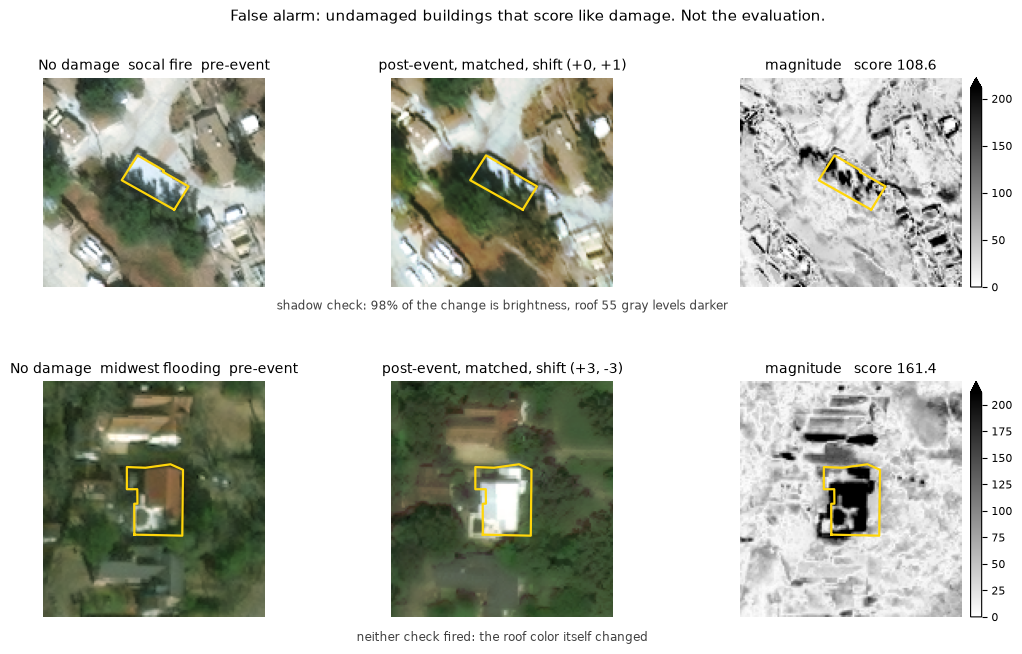

socal-fire_00000090 c421de81-701d-458b-a000-17eb7bd2c13c 108.610 575
midwest-flooding_00000003 4b50b3f5-3a98-4420-9488-59035b551e93 161.358 1101
  c421de81 shadow check: 98% of the change is brightness, roof 55 gray levels darker
  4b50b3f5 neither check fired: the roof color itself changed


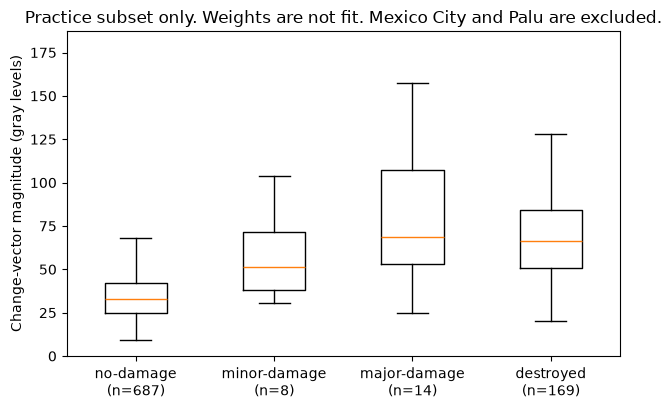

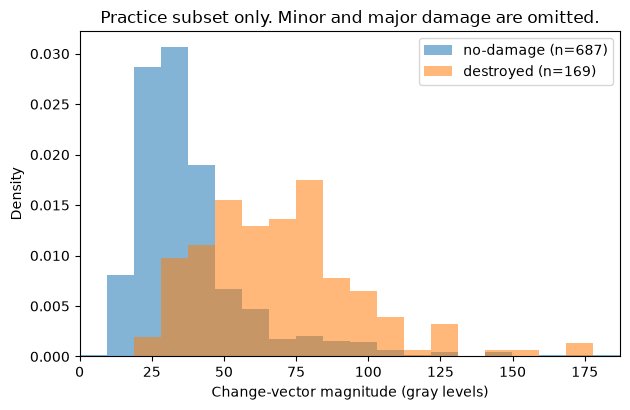

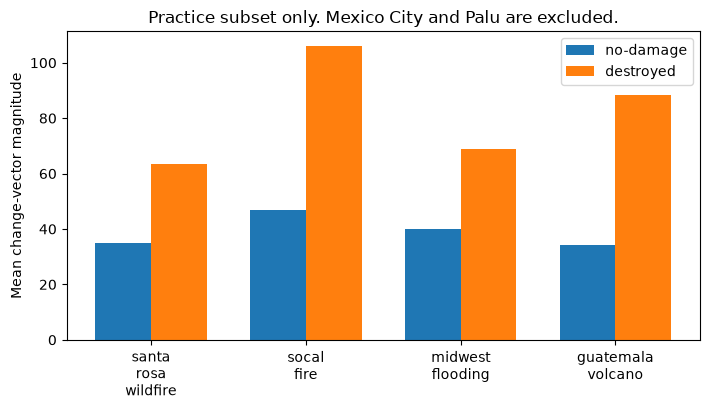

In [6]:
def crop_box(points, shape, margin=48):
    height, width = shape
    x0 = max(0, int(np.floor(points[:, 0].min())) - margin)
    y0 = max(0, int(np.floor(points[:, 1].min())) - margin)
    x1 = min(width, int(np.ceil(points[:, 0].max())) + margin)
    y1 = min(height, int(np.ceil(points[:, 1].max())) + margin)
    return x0, y0, x1, y1


def take_crop(image, box, dx=0, dy=0):
    x0, y0, x1, y1 = box
    height, width = image.shape[:2]
    src_x0 = min(max(x0 + dx, 0), width - 1)
    src_y0 = min(max(y0 + dy, 0), height - 1)
    src_x1 = min(max(x1 + dx, src_x0 + 1), width)
    src_y1 = min(max(y1 + dy, src_y0 + 1), height)
    crop = image[src_y0:src_y1, src_x0:src_x1]
    canvas = np.zeros((y1 - y0, x1 - x0) + image.shape[2:], dtype=image.dtype)
    dest_x = src_x0 - (x0 + dx)
    dest_y = src_y0 - (y0 + dy)
    canvas[dest_y:dest_y + crop.shape[0], dest_x:dest_x + crop.shape[1]] = crop
    return canvas


def draw_outline(axis, points, origin):
    relative = points - np.array(origin, dtype=np.float64)
    closed = np.vstack([relative, relative[:1]])
    axis.plot(closed[:, 0], closed[:, 1], color="#ffd60a", linewidth=1.6)
    axis.set_axis_off()


def event_name(image_id):
    return image_id.rsplit("_", 1)[0]


def magnitude_map(pre_crop, post_crop):
    difference = post_crop.astype(np.float64) - pre_crop.astype(np.float64)
    return np.sqrt((difference * difference).sum(axis=2))


cache = {}


def matched_pair(image_id):
    if image_id not in cache:
        pre, post, _ = load_pair(image_id)
        cache[image_id] = (pre, histogram_match(post, pre))
    return cache[image_id]


def magnitude_scale():
    values = []
    for image_id in SUBSET:
        pre, matched = matched_pair(image_id)
        for row in rows:
            if row["image_id"] != image_id:
                continue
            mask = interior_mask(row["points"], pre.shape[:2])
            pre_values, post_values = paired_colors(pre, matched, mask, row["dx"], row["dy"])
            difference = post_values.astype(np.float64) - pre_values.astype(np.float64)
            values.append(np.sqrt((difference * difference).sum(axis=1)))
    return float(np.percentile(np.concatenate(values), 99))


def shift_check(row, reach=12):
    pre, matched = matched_pair(row["image_id"])
    mask = interior_mask(row["points"], pre.shape[:2])
    best_score, best_dx, best_dy = row["score"], row["dx"], row["dy"]
    for dy in range(-reach, reach + 1):
        for dx in range(-reach, reach + 1):
            pre_values, post_values = paired_colors(pre, matched, mask, dx, dy)
            if pre_values.shape[0] < 0.9 * row["n_pixels"]:
                continue
            score = change_vector_magnitude(pre_values, post_values)
            if score < best_score:
                best_score, best_dx, best_dy = score, dx, dy
    if max(abs(best_dx), abs(best_dy)) == reach:
        return 0.0, best_dx, best_dy
    drop = 1.0 - best_score / row["score"] if row["score"] > 0 else 0.0
    return drop, best_dx, best_dy


def explain(row):
    if row.get("shift_drop", 0.0) >= 0.25:
        return (
            f"shift check: moving the post patch by ({row['probe_dx']:+d}, {row['probe_dy']:+d}) px "
            f"removes {row['shift_drop']:.0%} of the score"
        )
    if row["bright_share"] >= 0.75 and row["lum_change"] < 0:
        return (
            f"shadow check: {row['bright_share']:.0%} of the change is brightness, "
            f"roof {abs(row['lum_change']):.0f} gray levels darker"
        )
    return "neither check fired: the roof color itself changed"


def panel_cases(cases, path, suptitle, scale):
    fig, axes = plt.subplots(len(cases), 3, figsize=(10.0, 3.4 * len(cases)))
    if len(cases) == 1:
        axes = np.array([axes])
    for axis_row, case in zip(axes, cases):
        pre, matched = matched_pair(case["image_id"])
        box = crop_box(case["points"], pre.shape[:2])
        pre_crop = take_crop(pre, box)
        post_crop = take_crop(matched, box, case["dx"], case["dy"])
        magnitude = magnitude_map(pre_crop, post_crop)
        origin = (box[0], box[1])
        place = event_name(case["image_id"]).replace("-", " ")
        kind = "Destroyed" if case["subtype"] == "destroyed" else "No damage"
        axis_row[0].imshow(cv2.cvtColor(pre_crop, cv2.COLOR_BGR2RGB))
        axis_row[0].set_title(f"{kind}  {place}  pre-event", fontsize=10)
        axis_row[1].imshow(cv2.cvtColor(post_crop, cv2.COLOR_BGR2RGB))
        axis_row[1].set_title(
            f"post-event, matched, shift ({case['dx']:+d}, {case['dy']:+d})", fontsize=10
        )
        image = axis_row[2].imshow(magnitude, cmap="gray_r", vmin=0, vmax=scale)
        axis_row[2].set_title(f"magnitude   score {case['score']:.1f}", fontsize=10)
        for axis in axis_row:
            draw_outline(axis, case["points"], origin)
        bar = fig.colorbar(image, cax=axis_row[2].inset_axes([1.04, 0.0, 0.05, 1.0]), extend="max")
        bar.ax.tick_params(labelsize=8)
        if case["subtype"] == "no-damage":
            axis_row[1].text(
                0.5, -0.06, explain(case), transform=axis_row[1].transAxes,
                ha="center", va="top", fontsize=8.5, color="0.25",
            )
    fig.suptitle(suptitle, fontsize=11)
    fig.tight_layout()
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    for case in cases:
        print(case["image_id"], case["building_id"], f"{case['score']:.3f}", case["n_pixels"])


def visible_cases(subtype):
    pool = []
    for row in rows:
        if row["subtype"] != subtype or row["n_pixels"] < 250:
            continue
        points = row["points"]
        width = float(points[:, 0].max() - points[:, 0].min())
        height = float(points[:, 1].max() - points[:, 1].min())
        short = min(width, height)
        long = max(width, height)
        if short < 24 or long > 160 or long / short > 2.4:
            continue
        if points[:, 0].min() < 20 or points[:, 1].min() < 20:
            continue
        if points[:, 0].max() > 1004 or points[:, 1].max() > 1004:
            continue
        pool.append(row)
    return sorted(pool, key=lambda row: row["score"])


scale = magnitude_scale()
destroyed_pool = visible_cases("destroyed")
destroyed_high = destroyed_pool[-1]
destroyed_other = next(
    (row for row in reversed(destroyed_pool)
     if event_name(row["image_id"]) != event_name(destroyed_high["image_id"])),
    destroyed_pool[-2] if len(destroyed_pool) > 1 else destroyed_high,
)
panel_cases(
    [destroyed_high, destroyed_other],
    FIGURE_DIR / "examples_destroyed.png",
    "Real loss: destroyed buildings on the practice subset. Not the evaluation.",
    scale,
)

destroyed_median = float(np.median([row["score"] for row in rows if row["subtype"] == "destroyed"]))
intact_pool = [row for row in reversed(visible_cases("no-damage")) if row["score"] >= destroyed_median][:30]
if not intact_pool:
    intact_pool = list(reversed(visible_cases("no-damage")))[:2]
for row in intact_pool:
    row["shift_drop"], row["probe_dx"], row["probe_dy"] = shift_check(row)
shift_cases = [row for row in intact_pool if row["shift_drop"] >= 0.25]
shadow_cases = [
    row for row in intact_pool
    if row["shift_drop"] < 0.25 and row["bright_share"] >= 0.75 and row["lum_change"] < 0
]
chosen = [group[0] for group in (shift_cases, shadow_cases) if group]
for row in intact_pool:
    if len(chosen) == 2:
        break
    if row not in chosen:
        chosen.append(row)
panel_cases(
    chosen,
    FIGURE_DIR / "examples_intact.png",
    "False alarm: undamaged buildings that score like damage. Not the evaluation.",
    scale,
)
for row in chosen:
    print(" ", row["building_id"][:8], explain(row))

class_order = ["no-damage", "minor-damage", "major-damage", "destroyed"]
class_scores = [
    [row["score"] for row in rows if row["subtype"] == name]
    for name in class_order
]
top = float(np.percentile([row["score"] for row in rows], 99.5))
fig, axis = plt.subplots(figsize=(6.4, 4.2))
axis.boxplot(class_scores, showfliers=False)
axis.set_xticks(
    range(1, len(class_order) + 1),
    [f"{name}\n(n={len(values)})" for name, values in zip(class_order, class_scores)],
)
axis.set_ylabel("Change-vector magnitude (gray levels)")
axis.set_ylim(0, top)
axis.set_title("Practice subset only. Weights are not fit. Mexico City and Palu are excluded.")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "score_by_class.png", dpi=160, bbox_inches="tight")
plt.show()

bins = np.linspace(0, top, 21)
fig, axis = plt.subplots(figsize=(6.4, 4.2))
axis.hist(class_scores[0], bins=bins, density=True, alpha=0.55, label=f"no-damage (n={len(class_scores[0])})")
axis.hist(class_scores[3], bins=bins, density=True, alpha=0.55, label=f"destroyed (n={len(class_scores[3])})")
axis.set_xlabel("Change-vector magnitude (gray levels)")
axis.set_ylabel("Density")
axis.set_xlim(0, top)
axis.legend()
axis.set_title("Practice subset only. Minor and major damage are omitted.")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "score_histogram.png", dpi=160, bbox_inches="tight")
plt.show()

event_order = []
for image_id in SUBSET:
    event = event_name(image_id)
    if event not in event_order:
        event_order.append(event)
grouped = {}
for name in ("no-damage", "destroyed"):
    grouped[name] = []
    for event in event_order:
        values = np.array([
            row["score"]
            for row in rows
            if row["subtype"] == name and event_name(row["image_id"]) == event
        ])
        grouped[name].append(float(values.mean()) if values.size else np.nan)
positions = np.arange(len(event_order))
width = 0.36
fig, axis = plt.subplots(figsize=(7.2, 4.2))
axis.bar(positions - width / 2, grouped["no-damage"], width, label="no-damage")
axis.bar(positions + width / 2, grouped["destroyed"], width, label="destroyed")
axis.set_xticks(positions, [event.replace("-", "\n") for event in event_order])
axis.set_ylabel("Mean change-vector magnitude")
axis.legend()
axis.set_title("Practice subset only. Mexico City and Palu are excluded.")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "score_by_event.png", dpi=160, bbox_inches="tight")
plt.show()

## Partial numbers

A single threshold on the magnitude turns the score into a destroyed-versus-rest decision. The threshold is swept over the observed score range, as in the morphology notebook, and the chosen value has the highest destroyed-versus-rest F1 among those that keep the undamaged false-positive rate at or below 0.25. A false positive here is an undamaged building whose score is at least the threshold. This cut is provisional. It was fit on these 13 pairs only, and it will not be reused on Mexico City or Palu.

Precision, recall, and F1 use destroyed as the positive class and every other classified building as the negative class.

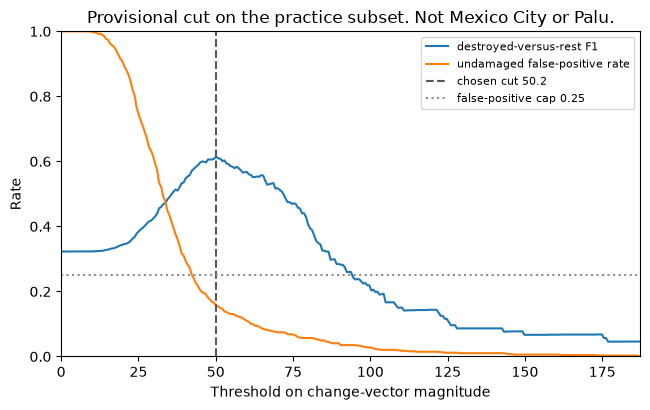

class, n, mean, median
no-damage, 687, 38.2666, 32.8255
minor-damage, 8, 58.6155, 51.2993
major-damage, 14, 79.7969, 68.5569
destroyed, 169, 73.3522, 66.2500
event, no-damage n, no-damage mean, destroyed n, destroyed mean
santa-rosa-wildfire, 208, 34.7944, 116, 63.5688
socal-fire, 61, 46.8560, 26, 106.0394
midwest-flooding, 321, 40.0621, 6, 68.7244
guatemala-volcano, 97, 34.3685, 21, 88.2468
threshold, 50.160, destroyed_f1, 0.6143, precision, 0.5139, recall, 0.7633
undamaged_false_positive_rate, 0.1557, tp, 129, fp, 122, fn, 40
subset is 13 practice pairs. This cut is not frozen and was not applied to Mexico City or Palu.


In [7]:
def binary_counts(y_true, y_pred):
    true_pos = int(np.sum(y_true & y_pred))
    false_pos = int(np.sum(~y_true & y_pred))
    false_neg = int(np.sum(y_true & ~y_pred))
    return true_pos, false_pos, false_neg


def f1_from_counts(true_pos, false_pos, false_neg):
    precision = true_pos / (true_pos + false_pos) if true_pos + false_pos else 0.0
    recall = true_pos / (true_pos + false_neg) if true_pos + false_neg else 0.0
    if precision + recall == 0:
        return 0.0, precision, recall
    return 2 * precision * recall / (precision + recall), precision, recall


scores = np.array([row["score"] for row in rows], dtype=np.float64)
destroyed = np.array([row["subtype"] == "destroyed" for row in rows])
undamaged = np.array([row["subtype"] == "no-damage" for row in rows])
max_score = max(float(np.ceil(scores.max())) if scores.size else 1.0, 1.0)
thresholds = np.round(np.linspace(0.0, max_score, 401), 3)
f1_curve = []
rate_curve = []
best = None
for cut in thresholds:
    predicted = scores >= cut
    undamaged_rate = float(predicted[undamaged].mean()) if undamaged.any() else 1.0
    true_pos, false_pos, false_neg = binary_counts(destroyed, predicted)
    f1_value, precision, recall = f1_from_counts(true_pos, false_pos, false_neg)
    f1_curve.append(f1_value)
    rate_curve.append(undamaged_rate)
    if undamaged_rate > 0.25:
        continue
    candidate = (f1_value, -undamaged_rate, cut, precision, recall, undamaged_rate, true_pos, false_pos, false_neg)
    if best is None or candidate > best:
        best = candidate

f1, _, threshold, precision, recall, undamaged_rate, true_pos, false_pos, false_neg = best

fig, axis = plt.subplots(figsize=(6.6, 4.2))
axis.plot(thresholds, f1_curve, label="destroyed-versus-rest F1")
axis.plot(thresholds, rate_curve, label="undamaged false-positive rate")
axis.axvline(threshold, color="0.35", linestyle="--", label=f"chosen cut {threshold:.1f}")
axis.axhline(0.25, color="0.55", linestyle=":", label="false-positive cap 0.25")
axis.set_xlim(0, float(np.percentile(scores, 99.5)))
axis.set_ylim(0, 1)
axis.set_xlabel("Threshold on change-vector magnitude")
axis.set_ylabel("Rate")
axis.legend(fontsize=8)
axis.set_title("Provisional cut on the practice subset. Not Mexico City or Palu.")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "threshold_curve.png", dpi=160, bbox_inches="tight")
plt.show()

lines = ["class, n, mean, median"]
for name in class_order:
    values = scores[np.array([row["subtype"] == name for row in rows])]
    if values.size == 0:
        lines.append(f"{name}, 0, , ")
        continue
    lines.append(f"{name}, {values.size}, {values.mean():.4f}, {np.median(values):.4f}")
lines.append("event, no-damage n, no-damage mean, destroyed n, destroyed mean")
for event in event_order:
    no_damage_values = [
        row["score"] for row in rows
        if row["subtype"] == "no-damage" and event_name(row["image_id"]) == event
    ]
    destroyed_values = [
        row["score"] for row in rows
        if row["subtype"] == "destroyed" and event_name(row["image_id"]) == event
    ]
    no_mean = f"{np.mean(no_damage_values):.4f}" if no_damage_values else ""
    destroyed_mean = f"{np.mean(destroyed_values):.4f}" if destroyed_values else ""
    lines.append(
        f"{event}, {len(no_damage_values)}, {no_mean}, {len(destroyed_values)}, {destroyed_mean}"
    )
lines.append(
    f"threshold, {threshold:.3f}, destroyed_f1, {f1:.4f}, precision, {precision:.4f}, recall, {recall:.4f}"
)
lines.append(
    f"undamaged_false_positive_rate, {undamaged_rate:.4f}, tp, {true_pos}, fp, {false_pos}, fn, {false_neg}"
)
lines.append("subset is 13 practice pairs. This cut is not frozen and was not applied to Mexico City or Palu.")
metrics_path = TABLE_DIR / "change_vector_metrics.txt"
metrics_path.write_text("\n".join(lines) + "\n")
print("\n".join(lines))

## What this run is, and what is left

The CSV, the example panels, and the charts are the progress material for the change-vector magnitude. They live under `outputs/change_vector/progress/`. The class means should be read with the subset in mind: most destroyed buildings here are fire losses, which change color strongly, and minor damage has only a handful of polygons.

Still open for this score: the same CSV on the remaining practice pairs, written later under `outputs/change_vector/final/`. After all five score tables exist, the drawings for the final report are one practice destruction, one practice false alarm, one Mexico City pair, and one Palu pair, with all five scores on the same footprints. Those drawings are illustrations, and nothing in them is a reason to change the formula.